<a href="https://colab.research.google.com/github/Hily30/datascience-hilyah/blob/main/EDA_Penjadwalan_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyek EDA Penjadwalan Mata Kuliah — Google Colab

Notebook ini membantu menjalankan proyek 600 jadwal **sintetis**. Bukan hasil optimasi.

**Persiapan:** unggah `Proyek_EDA_Penjadwalan.zip` ke folder utama **Drive Saya**, lalu jalankan sel berurutan dengan tombol ▶. Notebook ini memakai salinan di `/content`, bukan mengubah ZIP di Drive.

## 1. Hubungkan Google Drive
Berikan izin saat Google meminta akses.

In [2]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


## 2. Ekstrak proyek
Pastikan ZIP bernama `Proyek_EDA_Penjadwalan.zip` ada di Drive Saya. Menjalankan sel ini lagi akan menimpa salinan proyek di `/content/jadwal_eda`. ZIP di Drive tidak diubah.

In [9]:
from pathlib import Path
from zipfile import ZipFile

zip_path = Path("/content/drive/MyDrive/Proyek_EDA_Penjadwalan.zip")
if not zip_path.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {zip_path}. Periksa nama dan lokasi ZIP di Drive Saya.")
with ZipFile(zip_path) as z:
    z.extractall("/content")
print("Ekstraksi selesai. File proyek:")
print(*sorted(p.name for p in Path("/content/jadwal_eda").iterdir()), sep="\n")


Ekstraksi selesai. File proyek:
.venv
Laporan_EDA_Penjadwalan.docx
Laporan_EDA_Penjadwalan_Matakuliah.docx
Laporan_EDA_Penjadwalan_Matakuliah.pdf
Presentasi_EDA_Penjadwalan.pptx
README.md
__pycache__
analisis.py
app.py
buat_data.py
buat_laporan.py
buat_presentasi.py
data
grafik
hasil
requirements.txt
test_analisis.py
verifikasi.py


In [7]:
from zipfile import ZipFile

with ZipFile(zip_path) as zip_file:
    for nama in zip_file.namelist()[:30]:
        print(nama)

TUGAS 1 EDA/
TUGAS 1 EDA/.git/
TUGAS 1 EDA/.git/COMMIT_EDITMSG
TUGAS 1 EDA/.git/config
TUGAS 1 EDA/.git/description
TUGAS 1 EDA/.git/HEAD
TUGAS 1 EDA/.git/hooks/
TUGAS 1 EDA/.git/hooks/applypatch-msg.sample
TUGAS 1 EDA/.git/hooks/commit-msg.sample
TUGAS 1 EDA/.git/hooks/fsmonitor-watchman.sample
TUGAS 1 EDA/.git/hooks/post-update.sample
TUGAS 1 EDA/.git/hooks/pre-applypatch.sample
TUGAS 1 EDA/.git/hooks/pre-commit.sample
TUGAS 1 EDA/.git/hooks/pre-merge-commit.sample
TUGAS 1 EDA/.git/hooks/pre-push.sample
TUGAS 1 EDA/.git/hooks/pre-rebase.sample
TUGAS 1 EDA/.git/hooks/pre-receive.sample
TUGAS 1 EDA/.git/hooks/prepare-commit-msg.sample
TUGAS 1 EDA/.git/hooks/push-to-checkout.sample
TUGAS 1 EDA/.git/hooks/sendemail-validate.sample
TUGAS 1 EDA/.git/hooks/update.sample
TUGAS 1 EDA/.git/index
TUGAS 1 EDA/.git/info/
TUGAS 1 EDA/.git/info/exclude
TUGAS 1 EDA/.git/logs/
TUGAS 1 EDA/.git/logs/HEAD
TUGAS 1 EDA/.git/logs/refs/
TUGAS 1 EDA/.git/logs/refs/heads/
TUGAS 1 EDA/.git/logs/refs/heads/mai

In [8]:
from pathlib import Path
import shutil

sumber = Path("/content/TUGAS 1 EDA/jadwal_eda")
tujuan = Path("/content/jadwal_eda")

if not sumber.is_dir():
    print("Folder sumber belum ditemukan:", sumber)
    print("Kirimkan foto hasil ini untuk diperiksa.")
elif tujuan.exists():
    print("Folder tujuan sudah ada:", tujuan)
    print("Tidak ada file yang ditimpa.")
else:
    shutil.copytree(sumber, tujuan)
    print("Berhasil! Folder proyek siap di:", tujuan)

Berhasil! Folder proyek siap di: /content/jadwal_eda


In [11]:
%cd /content/jadwal_eda


/content/jadwal_eda


## 3. Instal pustaka
Sel ini mungkin memerlukan beberapa menit. Setelah runtime Colab dimulai ulang, instalasi perlu diulangi.

In [12]:
%pip install -q -r requirements.txt


## 4. Lihat data dummy
Satu baris merupakan satu pertemuan kelas mingguan, bukan satu mahasiswa.

In [13]:
import pandas as pd
df = pd.read_csv("data/jadwal_dummy_600.csv")
print("Ukuran data:", df.shape)
display(df.head())


Ukuran data: (600, 14)


,id_jadwal,kode_matakuliah,nama_matakuliah,sks,id_dosen,id_kelompok,jumlah_mahasiswa,id_ruang,kapasitas_ruang,hari,jam_mulai,jam_selesai,preferensi_dosen,preferensi_mahasiswa
0,JDW0001,MK07,Rekayasa Perangkat Lunak,3,DSN025,KLP016,27,R14,40,Jumat,10:20,12:50,Sore,Pagi
1,JDW0002,MK17,Komputer Vision,3,DSN067,KLP030,42,R18,50,Kamis,10:20,12:50,Pagi,Siang
2,JDW0003,MK16,Analisis dan Desain Sistem,3,DSN064,KLP036,44,R28,60,Selasa,16:20,18:50,Siang,Sore
3,JDW0004,MK10,Kecerdasan Buatan,3,DSN038,KLP040,37,R35,25,Selasa,13:00,15:30,Siang,Siang
4,JDW0005,MK05,Kalkulus,3,DSN017,KLP023,28,R18,50,Senin,14:40,17:10,Siang,Pagi


## 5. Jalankan EDA dan tes logika
Hasil berupa tabel dan grafik disimpan di folder `hasil` dan `grafik` pada salinan Colab.

In [14]:
!python analisis.py


{
  "baris": 600,
  "kolom_awal": 14,
  "mata_kuliah": 18,
  "dosen": 72,
  "kelompok": 60,
  "ruang": 35,
  "missing": {
    "id_jadwal": 0,
    "kode_matakuliah": 0,
    "nama_matakuliah": 0,
    "sks": 0,
    "id_dosen": 0,
    "id_kelompok": 0,
    "jumlah_mahasiswa": 0,
    "id_ruang": 0,
    "kapasitas_ruang": 0,
    "hari": 0,
    "jam_mulai": 0,
    "jam_selesai": 0,
    "preferensi_dosen": 47,
    "preferensi_mahasiswa": 46
  },
  "duplikat_penuh": 0,
  "duplikat_id_jadwal": 0,
  "duplikat_matkul_kelompok": 0,
  "waktu_invalid": 0,
  "durasi_sks_invalid": 0,
  "kapasitas_invalid": 0,
  "kapasitas_kurang": 182,
  "preferensi_dosen_valid_n": 553,
  "preferensi_mahasiswa_valid_n": 554,
  "preferensi_keduanya_valid_n": 512,
  "cocok_dosen_persen": 38.52,
  "cocok_mahasiswa_persen": 35.02,
  "rata_skor_keselarasan": 37.4,
  "bentrok_baris_total": 530,
  "bentrok_baris": {
    "dosen": 252,
    "kelompok": 305,
    "ruang": 420
  },
  "bentrok_pasangan": {
    "dosen": 161,
    "kel

In [15]:
!python -m unittest -v test_analisis


test_contoh_bentrok_data_dummy (test_analisis.TestAudit.test_contoh_bentrok_data_dummy) ... ok
test_contoh_kapasitas_dan_preferensi (test_analisis.TestAudit.test_contoh_kapasitas_dan_preferensi) ... ok
test_dataset (test_analisis.TestAudit.test_dataset) ... ok
test_invalid_dan_missing (test_analisis.TestAudit.test_invalid_dan_missing) ... ok
test_missing_preferensi_saat_waktu_valid (test_analisis.TestAudit.test_missing_preferensi_saat_waktu_valid) ... ok
test_overlap_dan_batas (test_analisis.TestAudit.test_overlap_dan_batas) ... ok

----------------------------------------------------------------------
Ran 6 tests in 3.337s

OK


## 6. Lihat ringkasan dan salah satu grafik

baris: 600
bentrok_baris_total: 530
kapasitas_kurang: 182
cocok_dosen_persen: 38.52
cocok_mahasiswa_persen: 35.02
rata_skor_keselarasan: 37.4


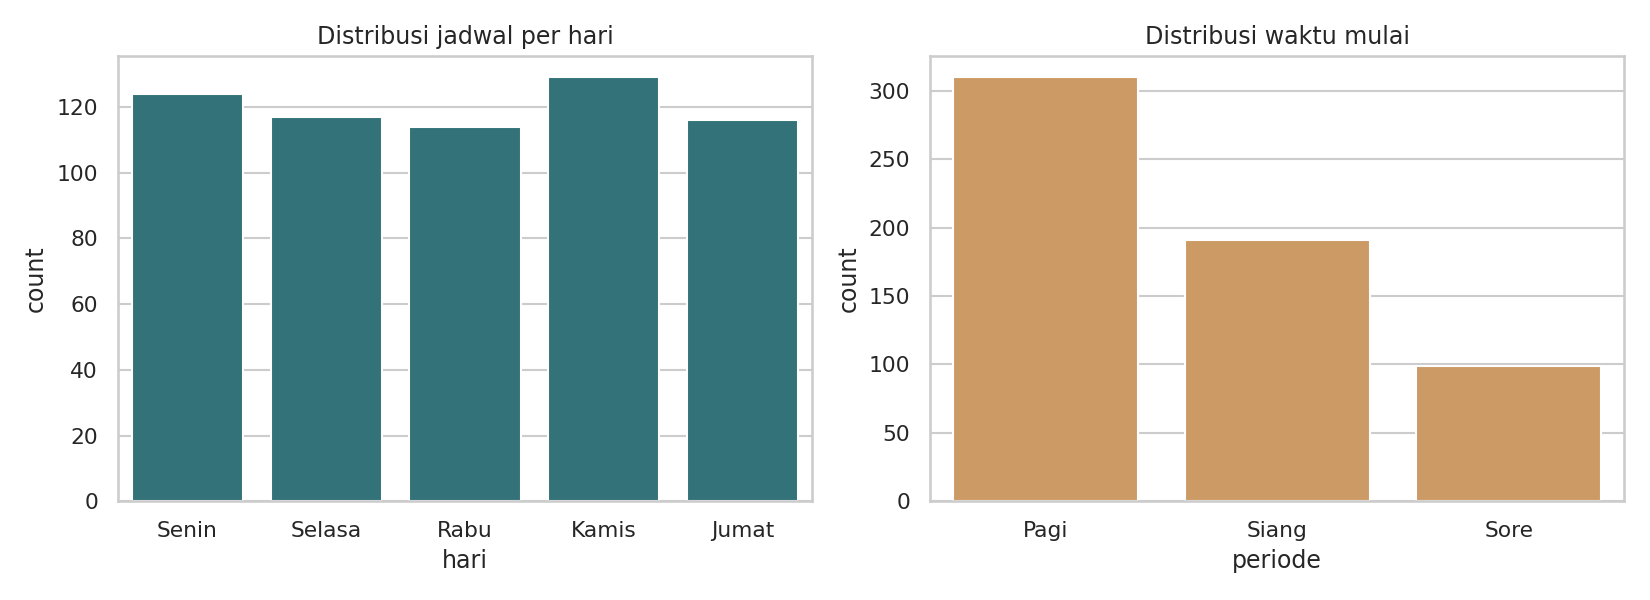

In [16]:
import json
from IPython.display import Image, display
with open("hasil/ringkasan.json", encoding="utf-8") as f:
    hasil = json.load(f)
for k in ["baris", "bentrok_baris_total", "kapasitas_kurang", "cocok_dosen_persen", "cocok_mahasiswa_persen", "rata_skor_keselarasan"]:
    print(f"{k}: {hasil[k]}")
display(Image(filename="grafik/01_distribusi.png"))


## 7. Buka aplikasi Streamlit di dalam Colab (opsional)
Aplikasi dijalankan di runtime Colab dan dicoba ditampilkan melalui iframe. Kompatibilitas tampilan bergantung pada browser dan sesi Colab. Jangan buka `localhost:8501` di browser komputer: itu adalah komputer Anda, bukan server Colab.

In [17]:
import subprocess, sys, time, requests
from google.colab import output
from google.colab.output import eval_js

# Hentikan server yang dibuat sel ini sebelumnya, jika sel dijalankan ulang.
if "streamlit_proses" in globals() and streamlit_proses.poll() is None:
    streamlit_proses.terminate()
    streamlit_proses.wait(timeout=10)

origin = eval_js("google.colab.kernel.proxyPort(8501)").rstrip("/")
log = open("/content/streamlit_log.txt", "w")
streamlit_proses = subprocess.Popen([
    sys.executable, "-m", "streamlit", "run", "app.py",
    "--server.address", "0.0.0.0", "--server.port", "8501",
    "--server.headless", "true", "--server.corsAllowedOrigins", origin
], stdout=log, stderr=subprocess.STDOUT)
for i in range(40):
    try:
        if requests.get("http://127.0.0.1:8501/_stcore/health", timeout=1).status_code == 200:
            break
    except requests.RequestException:
        pass
    if streamlit_proses.poll() is not None:
        raise RuntimeError("Streamlit berhenti. Lihat /content/streamlit_log.txt")
    time.sleep(1)
else:
    raise RuntimeError("Streamlit belum siap. Lihat /content/streamlit_log.txt")
output.serve_kernel_port_as_iframe(8501, height=900)


<IPython.core.display.Javascript object>

## 8. Simpan salinan proyek dan hasil ke Drive
Runtime `/content` bersifat sementara. Sel berikut membuat folder baru `hasil_eda_colab` di Drive Saya. Jika folder sudah ada, ubah nama tujuan agar hasil lama tidak tertimpa.

In [18]:
from pathlib import Path
import shutil

tujuan = Path("/content/drive/MyDrive/hasil_eda_colab")
if tujuan.exists():
    raise FileExistsError(f"{tujuan} sudah ada. Ubah nama folder tujuan sebelum menjalankan kembali.")
shutil.copytree("/content/jadwal_eda", tujuan, ignore=shutil.ignore_patterns("__pycache__", ".venv"))
print("Tersimpan di Drive:", tujuan)


Tersimpan di Drive: /content/drive/MyDrive/hasil_eda_colab


## Catatan penting
- ZIP telah berisi laporan Word, PPT, kode, dan dataset. Membuat ulang laporan/PPT dari skrip akan menimpa file laporan/PPT pada salinan Colab.
- `analisis.py` menulis ulang hasil EDA; `buat_data.py` membuat ulang data dummy sehingga jangan dijalankan jika tidak ingin mengganti CSV.
- Aplikasi ini memeriksa jadwal dan belum melakukan optimasi. Hasil dummy bukan hasil nyata kampus.
- Runtime Colab dapat terputus; simpan hasil ke Drive sebelum selesai.